# Çimento Dağıtım Ağı: Kapasite Kısıtlı Taşıma Modeli

**Soru:** Mevcut 10 tesislik ağ, 2025 talebini (nüfusa göre dağıtılmış) en düşük taşıma maliyetiyle nasıl karşılar? Yeni bir tesis nereye açılırsa maliyet en çok düşer?

**Gerçek veri:** tesis konumları ve kapasiteleri (şirket faaliyet raporu), 2025 il nüfusları (TÜİK ADNKS), 2025 ulusal çimento üretimi ve iç satışı (TÜRKÇİMENTO).

**Varsayımlar** (README'ye yaz): talep il nüfusuyla orantılı, mesafe = kuş uçuşu × 1,3 (alt sınır 20 km), şirket hacmi kapasite × doluluk × iç satış oranı.

Kurulum: `pip install "pulp<4" pandas matplotlib` (PuLP 4.x'in arayüzü farklı, bu notebook 3.x içindir).

In [1]:
import pandas as pd, numpy as np
import pulp
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.2f}".format

## 1. Parametreler

In [2]:
# --- VARSAYIMLAR ---
ULUSAL_IC_SATIS_MT = 63.77   # TÜRKÇİMENTO, 2025 çimento iç satışı (Mt)
ULUSAL_URETIM_MT   = 77.19   # TÜRKÇİMENTO, 2025 çimento üretimi (Mt)
DOLULUK            = 0.80    # Şirket tesislerinin ortalama doluluk varsayımı
MAKS_DOLULUK       = 0.95    # tek bir tesisin üst doluluk sınırı (varsayım)
ALT_SINIR_KM       = 20      # il içi en kısa mesafe (mesafe dosyalarıyla aynı)
VERI = "."                    # CSV dosyalarının klasörü

IC_SATIS_ORANI = ULUSAL_IC_SATIS_MT / ULUSAL_URETIM_MT   # üretimin iç satışa giden payı
print(f"İç satış oranı: {IC_SATIS_ORANI:.3f}")

İç satış oranı: 0.826


## 2. Veriyi oku ve kontrol et

In [3]:
iller = pd.read_csv(f"{VERI}/iller_nufus_2025.csv", encoding="utf-8-sig")
tesis = pd.read_csv(f"{VERI}/tesisler.csv", encoding="utf-8-sig")
koord = pd.read_csv(f"{VERI}/il_koordinatlari.csv", encoding="utf-8-sig")
d_ti  = pd.read_csv(f"{VERI}/mesafe_tesis_il_km.csv", index_col=0, encoding="utf-8-sig")  # tesis x il
d_ii  = pd.read_csv(f"{VERI}/mesafe_il_il_km.csv", index_col=0, encoding="utf-8-sig")     # il x il

assert iller["nufus_2025"].sum() == 86_092_168
assert abs(tesis["cimento_kapasite_mt_yil"].sum() - 22.5) < 1e-9
assert list(d_ti.columns) == list(iller["il"]) == list(d_ii.columns)

KAP = tesis.set_index("tesis")["cimento_kapasite_mt_yil"]
NUFUS_PAYI = iller.set_index("il")["nufus_2025"] / iller["nufus_2025"].sum()
tesis[["tesis", "tur", "il", "cimento_kapasite_mt_yil"]]

,tesis,tur,il,cimento_kapasite_mt_yil
0,Adana,Entegre,Adana,3.50
1,Aslan,Entegre,Kocaeli,3.30
2,Denizli,Entegre,Denizli,3.00
3,Ünye,Entegre,Ordu,2.75
4,Mardin,Entegre,Mardin,2.70
5,Bolu,Entegre,Bolu,2.50
6,Ankara,Entegre,Ankara,1.75
7,İskenderun I,Öğütme,Hatay,1.00
8,İskenderun II,Öğütme,Hatay,1.00
9,Ereğli,Öğütme,Zonguldak,1.00


## 3. Talep ve model

Şirketin karşılayacağı iç satış hacmi = toplam kapasite × doluluk × iç satış oranı. Bu hacim illere nüfus payına göre dağıtılır.

Model: her tesisten her ile taşınan miktar `x[i,j]` (Mt/yıl). Amaç toplam **Mt·km**'yi (milyon ton-km) en küçüklemek. Kısıtlar: her ilin talebi tam karşılanır, her tesis `kapasite × MAKS_DOLULUK`'u aşmaz.

In [4]:
def talep_hesapla(doluluk):
    hacim = KAP.sum() * doluluk * IC_SATIS_ORANI      # Mt/yıl
    return hacim, NUFUS_PAYI * hacim                   # il bazlı talep (Mt/yıl)

def tasima_modeli(talep, kap, d, maks_doluluk=MAKS_DOLULUK):
    """talep: Series (il->Mt), kap: Series (tesis->Mt), d: DataFrame (tesis x il, km).
    Döner: akış tablosu (tesis x il, Mt) ve toplam Mt·km."""
    T, J = list(kap.index), list(talep.index)
    assert kap.sum() * maks_doluluk >= talep.sum(), "Kapasite talebi karşılamıyor"
    prob = pulp.LpProblem("tasima", pulp.LpMinimize)
    x = {(a, b): pulp.LpVariable(f"x_{a}_{b}", lowBound=0) for a in range(len(T)) for b in range(len(J))}
    prob += pulp.lpSum(x[a, b] * float(d.loc[T[a], J[b]]) for a in range(len(T)) for b in range(len(J)))
    for a in range(len(T)):
        prob += pulp.lpSum(x[a, b] for b in range(len(J))) <= float(kap[T[a]]) * maks_doluluk
    for b in range(len(J)):
        prob += pulp.lpSum(x[a, b] for a in range(len(T))) == float(talep[J[b]])
    prob.solve(pulp.PULP_CBC_CMD(msg=False))
    assert pulp.LpStatus[prob.status] == "Optimal", pulp.LpStatus[prob.status]
    akis = pd.DataFrame([[x[a, b].value() for b in range(len(J))] for a in range(len(T))], index=T, columns=J)
    return akis, pulp.value(prob.objective)

## 4. Baz senaryo

In [5]:
hacim, talep = talep_hesapla(DOLULUK)
akis, maliyet = tasima_modeli(talep, KAP, d_ti)

yuk = akis.sum(axis=1)
ozet = pd.DataFrame({"kapasite_Mt": KAP, "yuk_Mt": yuk, "doluluk_%": yuk / KAP * 100})
print(f"Şirketin iç satış hacmi: {hacim:.2f} Mt/yıl  (kapasitenin %{hacim/KAP.sum()*100:.0f}'i)")
print(f"Toplam taşıma işi: {maliyet:,.0f} milyon ton-km  |  ağırlıklı ortalama mesafe: {maliyet/talep.sum():.0f} km")
ozet

Şirketin iç satış hacmi: 14.87 Mt/yıl  (kapasitenin %66'i)
Toplam taşıma işi: 2,435 milyon ton-km  |  ağırlıklı ortalama mesafe: 164 km


,kapasite_Mt,yuk_Mt,doluluk_%
Adana,3.50,1.34,38.32
Aslan,3.30,3.13,95.00
Denizli,3.00,2.83,94.25
Ünye,2.75,1.09,39.69
Mardin,2.70,2.21,81.76
Bolu,2.50,0.98,39.11
Ankara,1.75,1.66,95.00
İskenderun I,1.00,0.95,95.00
İskenderun II,1.00,0.03,2.90
Ereğli,1.00,0.65,64.86


**Not:** İskenderun I ve II aynı koordinatta olduğu için çözücü ikisi arasındaki dağılımı keyfi yapar. Yorumlarken aşağıdaki **il bazlı** özete bak.

In [6]:
ozet_il = ozet.join(tesis.set_index("tesis")["il"]).groupby("il")[["kapasite_Mt", "yuk_Mt"]].sum()
ozet_il["doluluk_%"] = ozet_il["yuk_Mt"] / ozet_il["kapasite_Mt"] * 100
ozet_il.sort_values("doluluk_%", ascending=False)

,kapasite_Mt,yuk_Mt,doluluk_%
il,,,
Ankara,1.75,1.66,95.00
Kocaeli,3.30,3.13,95.00
Denizli,3.00,2.83,94.25
Mardin,2.70,2.21,81.76
Zonguldak,1.00,0.65,64.86
Hatay,2.00,0.98,48.95
Ordu,2.75,1.09,39.69
Bolu,2.50,0.98,39.11
Adana,3.50,1.34,38.32


### Hangi il hangi tesisten besleniyor?

In [7]:
ana_tesis = akis.idxmax()                       # her ilin en büyük payı aldığı tesis
pay = akis.max() / akis.sum() * 100             # o tesisin payı (%)
atama = pd.DataFrame({"ana_tesis": ana_tesis, "pay_%": pay, "talep_Mt": talep}).sort_values("talep_Mt", ascending=False)
bolunen = (pay < 99.9).sum()
print(f"Birden fazla tesisten beslenen il sayısı: {bolunen}")
atama.head(15)

Birden fazla tesisten beslenen il sayısı: 3


,ana_tesis,pay_%,talep_Mt
İstanbul,Aslan,100.00,2.72
Ankara,Ankara,100.00,1.02
İzmir,Denizli,100.00,0.78
Bursa,Bolu,73.16,0.56
Antalya,Denizli,100.00,0.48
Konya,Ankara,71.51,0.40
Adana,Adana,100.00,0.39
Şanlıurfa,Mardin,100.00,0.39
Gaziantep,İskenderun I,92.45,0.38
Kocaeli,Ereğli,100.00,0.37


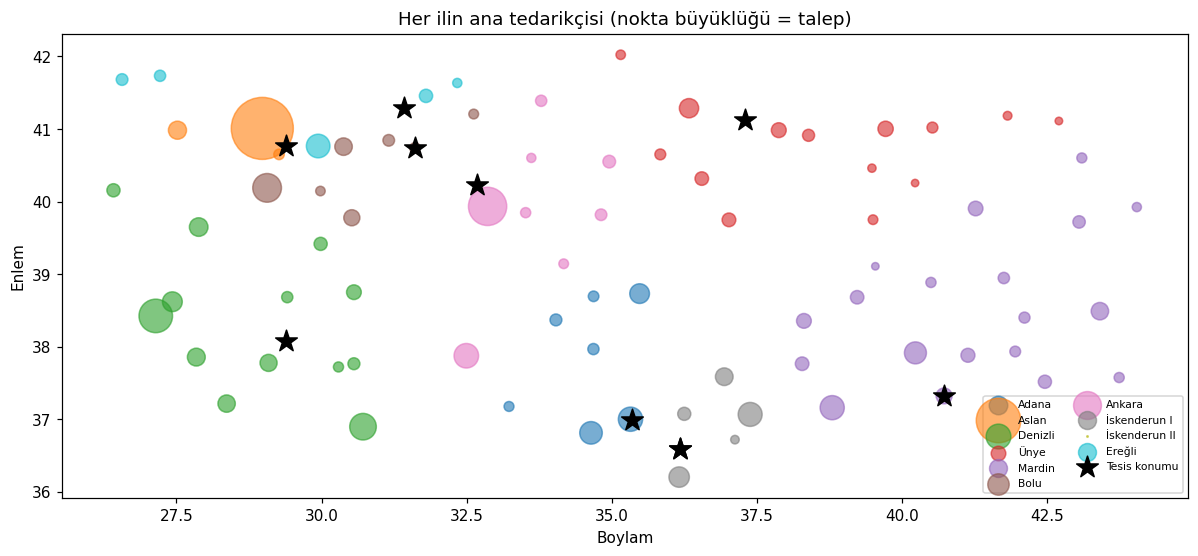

In [8]:
m = koord.merge(atama.reset_index().rename(columns={"index": "il"}), on="il")
fig, ax = plt.subplots(figsize=(11, 5.5))
cmap = plt.get_cmap("tab10")
for k, t in enumerate(KAP.index):
    s = m[m["ana_tesis"] == t]
    ax.scatter(s["boylam"], s["enlem"], s=s["talep_Mt"] * 600 + 15, color=cmap(k), alpha=.6, label=t)
    r = tesis[tesis["tesis"] == t].iloc[0]
tc = pd.read_csv(f"{VERI}/tesisler.csv", encoding="utf-8-sig")
ax.scatter(tc["boylam"], tc["enlem"], marker="*", s=220, c="k", zorder=5, label="Tesis konumu")
ax.set_xlabel("Boylam"); ax.set_ylabel("Enlem"); ax.set_aspect(1.25)
ax.set_title("Her ilin ana tedarikçisi (nokta büyüklüğü = talep)")
ax.legend(fontsize=7, ncol=2, loc="lower right")
plt.tight_layout(); plt.show()

## 5. Duyarlılık analizi: doluluk varsayımı

Baz doluluk (%80) gerçek veriye dayanmıyor. Sonuç bu varsayıma ne kadar duyarlı?

In [9]:
rows, ana = [], {}
for dl in [0.70, 0.80, 0.90]:
    h, t = talep_hesapla(dl)
    a, c = tasima_modeli(t, KAP, d_ti)
    ana[dl] = a.idxmax()
    rows.append({"doluluk": dl, "hacim_Mt": h, "Mt_km": c, "ort_km": c / t.sum()})
duy = pd.DataFrame(rows).set_index("doluluk")
duy["ana_tesisi_degismeyen_il_%"] = [(ana[d_] == ana[0.80]).mean() * 100 for d_ in duy.index]
duy

,hacim_Mt,Mt_km,ort_km,ana_tesisi_degismeyen_il_%
doluluk,,,,
0.70,13.01,"2,051.31",157.65,98.77
0.80,14.87,"2,435.22",163.76,100.00
0.90,16.73,"2,857.38",170.80,93.83


## 6. Yeni tesis aday analizi

Her ile varsayımsal 1 Mt kapasiteli bir tesis eklenir ve model yeniden çözülür. Sıralama, **taşıma işindeki azalmayı** gösterir. Bu bir ön eleme: yatırım maliyeti, arazi, klinker tedariki ve rakipler hesaba katılmaz.

In [10]:
def yeni_tesis_analizi(kap_mt=1.0, doluluk=DOLULUK):
    h, t = talep_hesapla(doluluk)
    _, baz = tasima_modeli(t, KAP, d_ti)
    sonuc = []
    for il in iller["il"]:
        ad = "YENI_" + il
        satir = d_ii.loc[il].copy(); satir[il] = ALT_SINIR_KM
        d2 = pd.concat([d_ti, satir.to_frame(ad).T])
        kap2 = pd.concat([KAP, pd.Series({ad: kap_mt})])
        _, c = tasima_modeli(t, kap2, d2)
        sonuc.append({"aday_il": il, "Mt_km": c, "azalma_Mt_km": baz - c, "azalma_%": (baz - c) / baz * 100})
    return baz, pd.DataFrame(sonuc).sort_values("azalma_Mt_km", ascending=False).reset_index(drop=True)

baz, aday = yeni_tesis_analizi()
print(f"Mevcut ağ: {baz:,.0f} Mt·km")
aday.head(10)

Mevcut ağ: 2,435 Mt·km


,aday_il,Mt_km,azalma_Mt_km,azalma_%
0,İzmir,"2,216.31",218.91,8.99
1,Manisa,"2,230.25",204.98,8.42
2,Bursa,"2,232.80",202.43,8.31
3,Tekirdağ,"2,236.45",198.78,8.16
4,İstanbul,"2,240.51",194.71,8.00
5,Balıkesir,"2,247.71",187.51,7.70
6,Yalova,"2,265.07",170.15,6.99
7,Kırklareli,"2,283.63",151.59,6.22
8,Çanakkale,"2,283.87",151.35,6.22
9,Kocaeli,"2,284.90",150.32,6.17


## 7. Power BI için dışa aktarım

Sonuçlar `powerbi/` klasörüne uzun formatta (her satır bir kayıt) yazılır. Power BI'a bu beş dosyayı yükle.

In [11]:
import os
os.makedirs("powerbi", exist_ok=True)
kaydet = lambda df, ad: df.rename(columns=lambda c: c.replace("_%", "_yuzde")).round(4).to_csv(f"powerbi/{ad}", index=False, encoding="utf-8-sig")

# 1) Akış: her tesis-il çifti (sıfır olmayanlar)
akis_uzun = akis.rename_axis(index="tesis", columns="il").stack().rename("miktar_Mt").reset_index()
akis_uzun = akis_uzun[akis_uzun["miktar_Mt"] > 1e-6].copy()
akis_uzun["mesafe_km"] = [d_ti.loc[t, i] for t, i in zip(akis_uzun["tesis"], akis_uzun["il"])]
akis_uzun["tasima_Mt_km"] = akis_uzun["miktar_Mt"] * akis_uzun["mesafe_km"]
kaydet(akis_uzun, "pbi_akis.csv")

# 2) İl tablosu: talep, nüfus, ana tedarikçi, koordinat
il_tablo = (koord.merge(iller[["il", "nufus_2025"]], on="il")
                 .merge(atama.reset_index().rename(columns={"index": "il"}), on="il"))
kaydet(il_tablo, "pbi_il_tablo.csv")

# 3) Tesis özeti: kapasite, yük, doluluk, koordinat
tesis_ozet = (ozet.join(tesis.set_index("tesis")[["tur", "il", "enlem", "boylam"]])
                  .rename_axis("tesis").reset_index())
kaydet(tesis_ozet, "pbi_tesis_ozet.csv")

# 4) Duyarlılık analizi
kaydet(duy.reset_index(), "pbi_duyarlilik.csv")

# 5) Yeni tesis adayları (koordinatlı)
kaydet(aday.merge(koord, left_on="aday_il", right_on="il").drop(columns="il"), "pbi_aday_tesis.csv")

print(sorted(os.listdir("powerbi")))

['pbi_aday_tesis.csv', 'pbi_akis.csv', 'pbi_duyarlilik.csv', 'pbi_il_tablo.csv', 'pbi_tesis_ozet.csv']


## 8. Sınırlamalar (README'ye taşı)

- Şirketin pazar payı her ilde aynı (~%23) varsayıldı; gerçekte bölgeden bölgeye değişir. Model, rakip fabrikaları ve hammadde (kireçtaşı) konumunu görmez, bu yüzden "boşluk" çıkan iller yatırım önerisi değil, taşıma açısından ön elemedir.
- Tesis üst doluluk sınırı (%95) sonucu etkiler: maliyet en düşük çözüm bazı tesisleri sınıra, bazılarını çok düşük doluluğa iter. Bu sınırı da duyarlılık analizine eklemeye değer.
- Talep nüfusla orantılı varsayıldı; çimento talebi inşaat faaliyetine bağlıdır. Yapı ruhsatı verisiyle bu analiz tekrarlanabilir.
- Klinker akışı modellenmedi: öğütme tesisleri (İskenderun, Ereğli) klinkeri dışarıdan alır, burada çimento üreten tesis gibi ele alındı.
- Mesafeler yaklaşık karayolu tahmini; gerçek karayolu mesafeleri ve nakliye maliyetleri (TL/ton-km) eklenebilir.
- Diğer üreticiler ve rakip fabrikalar yok; ihracat dışarıda bırakıldı.
- Doluluk oranı ve tek tesis üst sınırı (%95) varsayım.